# Stage 3: K = 3 ensembles and uncertainty

Each ensemble averages the test predictions of three FNOs trained with the same optimizer and
different seeds (0, 1, 2). No new training: predictions come from Stage 1A (Adam) and the Stage 2
finalists. Errors are in raw units against the dataset's test set.

| quantity | definition |
|---|---|
| ensemble prediction | $\bar y = \frac1K \sum_k \hat y_k$ |
| member spread | $s(x) = \sqrt{\frac1{K-1}\sum_k (\hat y_k - \bar y)^2}$ per pixel |
| relative $L^2$ | $\|\bar y - y\| / \|y\|$ per sample, then $\sum$ errors $/\sum$ norms as in the Trainer |
| resident state for training $K$ members at once | $K \times$ (parameters + optimizer state) |

## Setup

In [1]:
import sys, glob, os, importlib.util
if importlib.util.find_spec("neuralop") is None:
    !pip install -q neuraloperator
# project code (nsbench, optim, solver) comes from the private ns-surrogate-code dataset
hits = glob.glob("/kaggle/input/**/nsbench/__init__.py", recursive=True)
code_dir = (os.path.dirname(os.path.dirname(hits[0])) if hits else
            next(os.path.abspath(d) for d in (".", "..") if os.path.isdir(f"{d}/nsbench")))
sys.path.insert(0, code_dir)
import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nsbench
from nsbench import Trainer, save_csv, save_fig, save_predictions, run_record
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.DataFrame([{"python": sys.version.split()[0], "torch": torch.__version__,
               "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               "code": code_dir}])
from nsbench.data import find_data_dir
import glob
from pathlib import Path
from scipy.stats import spearmanr

/home/jaygupta/projects/FML_Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Test targets in raw units

In [2]:
te = torch.load(f"{find_data_dir()}/nsforcing_test_128.pt")
y = te["y"].double()
tr = torch.load(f"{find_data_dir()}/nsforcing_train_128.pt")["y"]
perm = torch.randperm(len(tr), generator=torch.Generator().manual_seed(0))
y_tr = tr[perm][: int(0.8 * len(tr))].float()
y_mean, y_std = y_tr.mean().double(), y_tr.std().double()        # same train statistics as nsbench.load
del tr, y_tr
pd.DataFrame([{"test samples": len(y), "y_mean (train)": y_mean.item(), "y_std (train)": y_std.item()}])

,test samples,y_mean (train),y_std (train)
0,2000,2.165325e-11,0.707791


## Available predictions

In [3]:
PRED_DIRS = sorted(glob.glob("kaggle_out/*/preds"))
files = {Path(p).stem: p for d in PRED_DIRS for p in glob.glob(f"{d}/*.npy")}
GROUPS = {"Adam": "fno_adam_seed{}", "GaLore r=16": "fno_GaLore_r_16_seed{}", "GaLore r=8": "fno_GaLore_r_8_seed{}",
          "GaLore r=4": "fno_GaLore_r_4_seed{}", "adaptive tau=0.999": "fno_adaptive_tau_0.999_seed{}",
          "adaptive tau=0.99": "fno_adaptive_tau_0.99_seed{}"}
avail = {g: [files.get(p.format(s)) for s in (0, 1, 2)] for g, p in GROUPS.items()}
avail = {g: f for g, f in avail.items() if all(f)}
pd.DataFrame([{"optimizer": g, "members": len(f)} for g, f in avail.items()])

,optimizer,members
0,Adam,3


## Ensemble accuracy and spread

In [4]:
def rel(p, t):
    return ((p - t).flatten(1).norm(dim=1).sum() / t.flatten(1).norm(dim=1).sum()).item()

rows, per_sample, ens_preds = [], [], {}
for g, fs in avail.items():
    P = torch.stack([torch.from_numpy(np.load(f).astype(np.float64)) for f in fs]) * y_std + y_mean   # [K, N, n, n]
    mean, spread = P.mean(0), P.std(0, unbiased=True)
    err = (mean - y).flatten(1).norm(dim=1) / y.flatten(1).norm(dim=1)
    sprd = spread.flatten(1).norm(dim=1) / y.flatten(1).norm(dim=1)
    rho = spearmanr(sprd.numpy(), err.numpy()).correlation
    members = [rel(P[k], y) for k in range(len(fs))]
    rows.append({"optimizer": g, "member rel L2 mean": np.mean(members), "member rel L2 std": np.std(members, ddof=1),
                 "ensemble rel L2": rel(mean, y), "gain vs mean member": 1 - rel(mean, y) / np.mean(members),
                 "spread / error (mean)": (sprd / err).mean().item(), "Spearman(spread, error)": rho})
    per_sample.append(pd.DataFrame({"optimizer": g, "sample": range(len(y)), "rel_L2": err.numpy(), "rel_spread": sprd.numpy()}))
    ens_preds[g] = mean
ens = pd.DataFrame(rows)
save_csv(ens, "stage3_ensembles")
save_csv(pd.concat(per_sample, ignore_index=True), "stage3_per_sample")
ens

[SAVED] results/stage3_ensembles.csv
[SAVED] results/stage3_per_sample.csv


,optimizer,member rel L2 mean,member rel L2 std,ensemble rel L2,gain vs mean member,spread / error (mean),"Spearman(spread, error)"
0,Adam,0.036404,0.001933,0.030995,0.148569,0.75149,0.547312


## Error by frequency band (ensembles)

In [5]:
from nsbench.analysis import band_errors
bands = band_errors({g: p.float() for g, p in ens_preds.items()}, y.float())
save_csv(bands, "stage3_band_errors")
bands

[SAVED] results/stage3_band_errors.csv


,model,low (k < 8),mid (8 ≤ k ≤ 32),high (k > 32)
0,Adam,0.000357,0.132895,1.219516


## Does the spread flag the hard samples?

[SAVED] figures/stage3_spread_vs_error.png


PosixPath('figures/stage3_spread_vs_error.png')

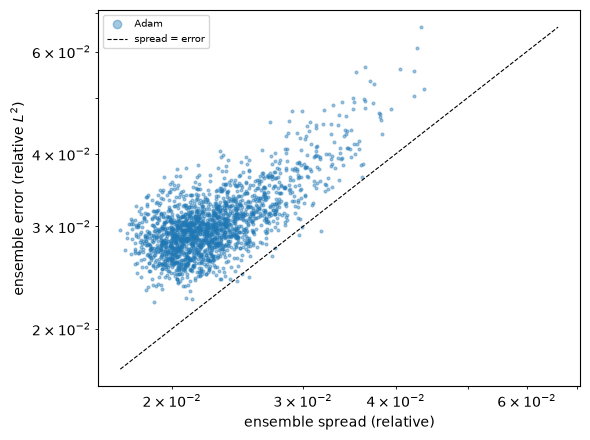

In [6]:
S = pd.concat(per_sample, ignore_index=True)
fig, ax = plt.subplots(figsize=(6, 4.5))
for g, s in S.groupby("optimizer", sort=False):
    ax.scatter(s.rel_spread, s.rel_L2, s=4, alpha=0.4, label=g)
lim = [S[["rel_spread", "rel_L2"]].min().min(), S[["rel_spread", "rel_L2"]].max().max()]
ax.plot(lim, lim, "k--", lw=0.8, label="spread = error")
ax.set(xscale="log", yscale="log", xlabel="ensemble spread (relative)", ylabel="ensemble error (relative $L^2$)")
ax.legend(fontsize=7, markerscale=3); fig.tight_layout()
save_fig("stage3_spread_vs_error", fig)